## T-750-SMAC: Statistical Modelling and Computation <br> **Week 2 Notebook - Network Data**
#### Created by: Nidia Guadalupe López Flores (nidiaf@ru.is)

In [29]:
import networkx as nx
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import metrics

### 1 - Network elements

Networks are formed from a set of nodes (or vertices) and a set of links (or edges) describing the connections among such nodes. Different types of networks exist, depending on their characteristics. In the following we will show you the basics for creating and analysing networks of three main types: undirected, directed, and weighted networks. 

In [30]:
## Creating a network. You can name your network any name that you like the most.

G_undirected = nx.Graph()  #Creates an undirected graph
G_directed = nx.DiGraph()  #Creates a directed graph
G_weighted = nx.Graph()  #Both directed and undirected graphs can also be weighted networks. 

You can use the networkx commands **G.number_of_nodes()**, and **G.number_of_edges()** to inspect the number of nodes and edges in a given network. 

In [31]:
print('Number of nodes in G_undirected: ', G_undirected.number_of_nodes())
print('Number of edges in G_undirected: ', G_undirected.number_of_edges())

Number of nodes in G_undirected:  0
Number of edges in G_undirected:  0


#### 1.1 Nodes, edges, direction, and weights

There are different ways to create or add nodes to an existent network. The code below shows you three ways: manually one node at a time, several nodes at the same time, or based on a list of elements. 

In [32]:
#Adding nodes manually one by one
G_undirected.add_node(0)
G_undirected.add_node(1)

#Adding nodes manually in batch
G_undirected.add_nodes_from(nodes_for_adding=[2,3,4,5])

#Adding nodes from a list
nodes_to_add = [6,7,8]
G_undirected.add_nodes_from(nodes_to_add)

In this and the following examples we will use the Networkx function **nx.draw_networkx(G = Graph_name, with_labels = True)** to plot the resulting networks so you can better visualise the networks features. This function has several parameters that you can customise to  make your network plot look better, including node and edges sizes, colour, transparency, and labels, as well as edges width, and arrow type. You can get a full list of these paramenters here: https://networkx.org/documentation/stable/reference/generated/networkx.drawing.nx_pylab.draw_networkx.html 

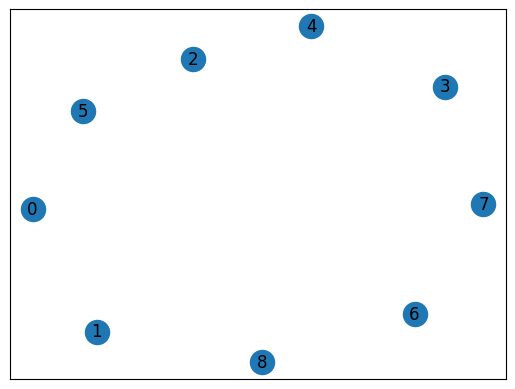

In [33]:
nx.draw_networkx(G_undirected, with_labels=True)

Similarly, there are multiple ways to create or add edges to an existent network. The code below shows three ways: one edge at a time, several edges at the same time, or add edges based on a list. 

In [34]:
#Adding edges manually one by one
G_undirected.add_edge(0, 1)
G_undirected.add_edge(1, 2)

#Adding edges manually in batch
G_undirected.add_edges_from([(1, 4),(2,1),(2,3)])

#Adding edges from a list. 
edges_to_add = [(4,5), (5, 7), (9,10)]  
G_undirected.add_edges_from(edges_to_add) 

Note that adding edges that include nodes that do not exist in the network yet will **not** raise an error but will add the unknown nodes to the graph. 

In [35]:
print('Nodes in G_undirected: ', G_undirected.nodes())
print('Edges in G_undirected: ', G_undirected.edges())

Nodes in G_undirected:  [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Edges in G_undirected:  [(0, 1), (1, 2), (1, 4), (2, 3), (4, 5), (5, 7), (9, 10)]


Once the nodes and edges have been added you can get the list of neighbours a node has: 

In [36]:
list(G_undirected.neighbors(n=1))

[0, 2, 4]

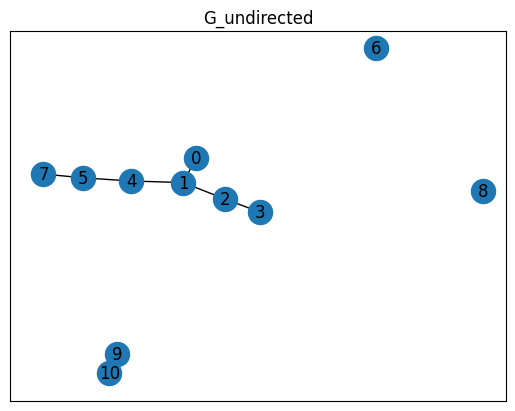

In [37]:
plt.title('G_undirected')
nx.draw_networkx(G_undirected, with_labels=True)


In the case of the directed network, edges can be added using the same code, with the difference that the edges created will take into accont the order of the nodes as (source, target). That is, the edge (0,1) in a directed graph will go from node 0 towards node 1. 

In [38]:
#Adding edges manually one by one
G_directed.add_edge(0, 1) 
G_directed.add_edge(1, 0) 
G_directed.add_edge(1, 2)

#Adding edges manually in batch
G_directed.add_edges_from([(1, 4),(2, 1),(2, 3)])

#Adding edges from a list. 
edges_to_add = [(4,5), (5, 7), (9,10)]  
G_directed.add_edges_from(edges_to_add) 


In [39]:
print('Nodes in G_directed: ', G_directed.nodes())
print('Edges in G_directed: ', G_directed.edges())

Nodes in G_directed:  [0, 1, 2, 4, 3, 5, 7, 9, 10]
Edges in G_directed:  [(0, 1), (1, 0), (1, 2), (1, 4), (2, 1), (2, 3), (4, 5), (5, 7), (9, 10)]


Similarly, once the nodes and edges have been added you can get the list of predecessors (nodes that connect to) and successors (nodes reached by) of a node.

In [40]:
list(G_directed.predecessors(n=1))

[0, 2]

In [41]:
list(G_directed.successors(n=1))

[0, 2, 4]

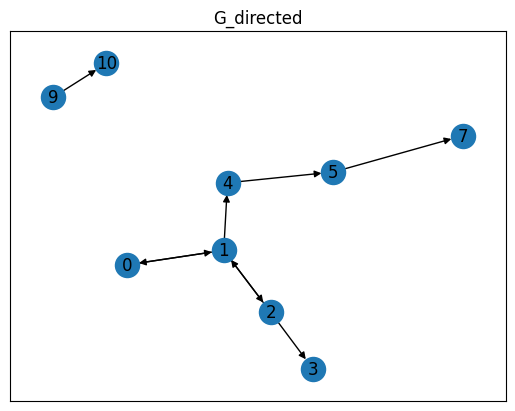

In [42]:
plt.title('G_directed')
nx.draw_networkx(G_directed, with_labels=True)

In the case of the weighted networks, along with the nodes being connected, the edges are created including values that are used as weights for the edges. These values can be for example, distances (e.g. nodes are cities and edges how far they are), frequencies (e.g. nodes are airports and edges connecting flights or nodes are people and edges number of phonecalls), etc. 

These *weights* can be added using the same code, with the difference that we include the weight value as a third parameter, i.e. (source, target, weight). 

The name **"weight"** in this example, is how we decided naming this edge feature, but you could select any other name, as well as include more than one feature, for example, capacity, lenght, size, etc. 

In [43]:
#Adding edges manually one by one
G_weighted.add_edge( 0,1, weight = 3)

#Adding edges manually in batch
G_weighted.add_weighted_edges_from([(1,4,1),(2,1,2),(2,3,5)])

#Adding edges from a list. 
edges_to_add = [(4,5,6), (5,7,10), (9,10,2)]  
G_weighted.add_weighted_edges_from(edges_to_add) 

In [44]:
print('Nodes in G_weighted: ', G_weighted.nodes())
print('Edges in G_weighted: ',G_weighted.edges(data=True))

Nodes in G_weighted:  [0, 1, 4, 2, 3, 5, 7, 9, 10]
Edges in G_weighted:  [(0, 1, {'weight': 3}), (1, 4, {'weight': 1}), (1, 2, {'weight': 2}), (4, 5, {'weight': 6}), (2, 3, {'weight': 5}), (5, 7, {'weight': 10}), (9, 10, {'weight': 2})]


In the following example, we will plot the network with the weights as the edge widht. Alternatively, you could also put the weights as edge labels. 

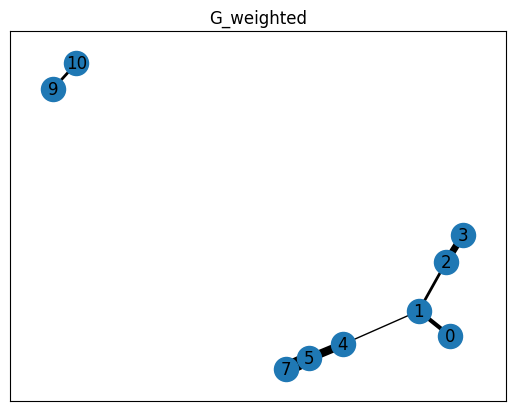

In [45]:
weights = [d for (u,v,d) in G_weighted.edges(data='weight')] #Creates a list that contains the weights of each edge to be used as the width of the edge in the plot. 

plt.title('G_weighted')
nx.draw_networkx(G_weighted, with_labels=True, width = weights) #We set the edges width as the weight each edge has.  

##### Making networks reading from files

In addition to manually creating graphs, adding nodes, and edges, it is possible to create networks direcly from files, for example, edgelists, adjacency lists, csv and txt files. 

Edge List

In [46]:
G = nx.read_edgelist("sample files//karate.edgelist") #Additional parameters: create_using=nx.DiGraph (for directed graphs), 

#plt.title('Karate Edgelist File')
#nx.draw_networkx(G, with_labels=True, node_color = 'lightblue')

Adjacency List

In [47]:
G = nx.read_adjlist('sample files//amigos.adjlist')

#plt.title('Friends Adjacency List File')
#nx.draw_networkx(G, with_labels=True, node_size =1500, node_color = 'pink')

CSV and TXT files

Alternatively, you can rely on the funcions **from_pandas_adjacency**, **from_pandas_edgelist**, and **from_numpy_array** to create networks. These files can be both created in python or read in csv/txt form.

In [48]:
df = nx.to_pandas_adjacency(nx.florentine_families_graph())
G = nx.from_pandas_adjacency(df)

#plt.title('Graph from pandas adjacency matrix')
#nx.draw_networkx(G, with_labels=True, node_size =1000, node_color = 'orchid')

In [49]:
df = nx.to_pandas_edgelist(nx.krackhardt_kite_graph())
G = nx.from_pandas_edgelist(df)

#plt.title('Graph from pandas edgelist')
#nx.draw_networkx(G, with_labels=True, node_size =500, node_color = 'red')

In [50]:
df = nx.to_numpy_array(nx.petersen_graph())
G = nx.from_numpy_array(df)

#plt.title('Graph from numpy array')
#nx.draw_networkx(G, with_labels=True, node_size =500, node_color = 'lightgreen')

#### 1.2 Density, degree, and strength

Density in a network is the ratio of the number of actual edges to the maximum possible edges between nodes, representing how interconnected the network is. 

In [51]:
G_complete = nx.complete_graph(n=30) #Sample network
print('Density of a complete graph: ', nx.density(G= G_complete))

print('Density of an undirected graph: ', nx.density(G= G_undirected))

print('Density of a directed graph: ', nx.density(G= G_directed))

Density of a complete graph:  1.0
Density of an undirected graph:  0.12727272727272726
Density of a directed graph:  0.125


The degree of a node is the number of edges connected to it, representing its direct relationships in the network. In a directed graph, it is divided into in-degree (incoming edges) and out-degree (outgoing edges).

In [52]:
# Getting the degree of a specific node in the network.

df = nx.to_pandas_adjacency(nx.florentine_families_graph())
G = nx.from_pandas_adjacency(df)

print('Node named ', list(G.nodes())[1], ' has degree equal to: ', G.degree(list(G.nodes())[1])) #Note that instead of list(G.nodes())[1] you could simply write 'Medici' or any other node name

# Getting the degrees of all nodes in the network

print(G.degree())

#Getting the in-degree and out-degree in a directed network

print('In-degree of Network G_directed; ', G_directed.in_degree()) #You can also declare a specific node name. 
print('Out-degree of Network G_directed; ', G_directed.out_degree()) #You can also declare a specific node name.

Node named  Medici  has degree equal to:  6
[('Acciaiuoli', 1), ('Medici', 6), ('Castellani', 3), ('Peruzzi', 3), ('Strozzi', 4), ('Barbadori', 2), ('Ridolfi', 3), ('Tornabuoni', 3), ('Albizzi', 3), ('Salviati', 2), ('Pazzi', 1), ('Bischeri', 3), ('Guadagni', 4), ('Ginori', 1), ('Lamberteschi', 1)]
In-degree of Network G_directed;  [(0, 1), (1, 2), (2, 1), (4, 1), (3, 1), (5, 1), (7, 1), (9, 0), (10, 1)]
Out-degree of Network G_directed;  [(0, 1), (1, 3), (2, 2), (4, 1), (3, 0), (5, 1), (7, 0), (9, 1), (10, 0)]


In [53]:
G = nx.read_edgelist("sample files//karate.edgelist")

print('Node 0 has degree: ',G.degree(nbunch= '0')) #Just counts the number of connections 
print('Node 0 has strength: ',G.degree(nbunch='0',weight='weight')) #Takes into account the weight of the edges connecting to and from node 0

## In and out strength can also be computed by adding the parmeter weight='name_of_strenght_variable' to the functions G.in_degree(), and G.out_degree()

Node 0 has degree:  16
Node 0 has strength:  42


#### 1.3 Network representations

Network representations refer to ways of encoding the graph structure for analysis. It is typically done in formats like adjacency matrices and edge lists. These representations include nodes and edges, as well as their attibutes. 

##### Adjacency matrix

In [54]:
A = nx.adjacency_matrix(G=G)
Adj_mat = A.toarray() #Stores a numpy array of dimensions n_nodes x n_nodes. 

##### Adjacency list

The first element in adjacency lists corresponds to the source node, with the subsequent nodes as its targets. 

In [55]:
# Generate adjacency list

adjlist_g = list(nx.generate_adjlist(G=G)) #In this example G is the karate network that we created a few examples above. 
adjlist_g

['0 1 2 3 4 5 6 7 8 10 11 12 13 17 19 21 31',
 '1 2 3 7 13 17 19 21 30',
 '2 3 7 8 9 13 27 28 32',
 '3 7 12 13',
 '4 6 10',
 '5 6 10 16',
 '6 16',
 '7',
 '8 30 32 33',
 '10',
 '11',
 '12',
 '13 33',
 '17',
 '19 33',
 '21',
 '31 24 25 28 32 33',
 '30 32 33',
 '9 33',
 '27 23 24 33',
 '28 33',
 '32 14 15 18 20 22 23 29 33',
 '16',
 '33 14 15 18 20 22 23 26 29',
 '14',
 '15',
 '18',
 '20',
 '22',
 '23 25 29',
 '25 24',
 '29 26',
 '24',
 '26']

In [56]:
# Writing/Saving adjacency lists 

nx.write_adjlist(G=G, path='sample files/sample_adjlist.adjlist')

In [57]:
# Reading adjlist
G = nx.read_adjlist('sample files/sample_adjlist.adjlist')

##### Edgelist

In [58]:
# Generate edgelist 

edgelist_g = list(nx.generate_edgelist(G=G_undirected, data=False))
edgelist_g

['0 1', '1 2', '1 4', '2 3', '4 5', '5 7', '9 10']

In [59]:
edgelist_g = list(nx.generate_edgelist(G=G_weighted, data=True))
edgelist_g

["0 1 {'weight': 3}",
 "1 4 {'weight': 1}",
 "1 2 {'weight': 2}",
 "4 5 {'weight': 6}",
 "2 3 {'weight': 5}",
 "5 7 {'weight': 10}",
 "9 10 {'weight': 2}"]

In [60]:
# Writing/Saving edgelists 

nx.write_edgelist(G=G_undirected, path='sample files/sample_edgelist.edgelist')
# Reading edgelist
G = nx.read_edgelist('sample files/sample_edgelist.edgelist')  


nx.write_weighted_edgelist(G=G_weighted, path='sample files/sample_w_edgelist.weighted.edgelist')
# Reading weighted edgelist
G_weighted = nx.read_weighted_edgelist('sample files/sample_w_edgelist.weighted.edgelist')
G_weighted.edges(data=True)

EdgeDataView([('0', '1', {'weight': 3.0}), ('1', '4', {'weight': 1.0}), ('1', '2', {'weight': 2.0}), ('4', '5', {'weight': 6.0}), ('2', '3', {'weight': 5.0}), ('5', '7', {'weight': 10.0}), ('9', '10', {'weight': 2.0})])

### 2 - Small worlds

#### 2.1 Assortativity

Assortativity measures the tendency of nodes in a network to connect with similar nodes based on a specific attribute (either numerical or categorical). A network with high assortativity shows nodes preferentially linking to others with similar traits, while disassortative networks show connections between dissimilar nodes.

Example with categorical attribute: 

In [61]:
## Example with categorical attribute: 

G_karate = nx.karate_club_graph()
nx.attribute_assortativity_coefficient( G_karate, attribute='club')

0.717530864197531

Example with a numerical attribute: 

For the next example, we will add a numerical attribute to the Karate network. We will name it 'age'. 

In [62]:
for node in G_karate.nodes():
    G_karate.nodes[node]['age'] = node*2 + 25

In [63]:
list(G_karate.nodes(data=True))[0:5]

[(0, {'club': 'Mr. Hi', 'age': 25}),
 (1, {'club': 'Mr. Hi', 'age': 27}),
 (2, {'club': 'Mr. Hi', 'age': 29}),
 (3, {'club': 'Mr. Hi', 'age': 31}),
 (4, {'club': 'Mr. Hi', 'age': 33})]

In [64]:
## Example with a numerical attribute: 

nx.numeric_assortativity_coefficient(G_karate, attribute='age')

0.44804878806390486

Assortativity computed based on the nodes' degree measures the tendency of nodes to connect with other nodes that have similar degrees. A positive degree assortativity indicates that high-degree nodes are more likely to connect with other high-degree nodes, while a negative value indicates that high-degree nodes tend to connect with low-degree nodes.

In [65]:
nx.degree_assortativity_coefficient(G_karate)

-0.47561309768461413

In [66]:
nx.degree_assortativity_coefficient(G_karate, weight='weight')

-0.5072641493979262

#### 2.1 Paths

A path in a network represents a route between two nodes, showing the connections traversed along the way.

The average shortest path length in the Karate Club network is: 2.408199643493761 
The shortest path between nodes 1 and 33 in the Karate club network has 2 steps lenght: [1, 13, 33]


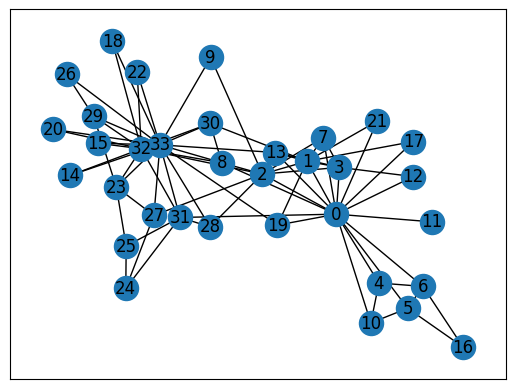

In [67]:
asp = nx.average_shortest_path_length(G= G_karate) #G must be a connected network 
path = nx.shortest_path(G_karate, source=1, target=33)
path_length = nx.shortest_path_length(G_karate, source=1, target=33)

print(f'The average shortest path length in the Karate Club network is: {asp} ')

print(f'The shortest path between nodes 1 and 33 in the Karate club network has {path_length} steps lenght: {path}')

nx.draw_networkx(G=G_karate, with_labels=True)

#### 2.2 Connectedness 

A network is connected if there is a path between any two nodes in the network. Disconnected networks can have multiple connected components. 

In [68]:
print(f'Is the Karate club network connected?: {nx.is_connected(G=G_karate)}')

Is the Karate club network connected?: True


Is the Amigos network connected?: False


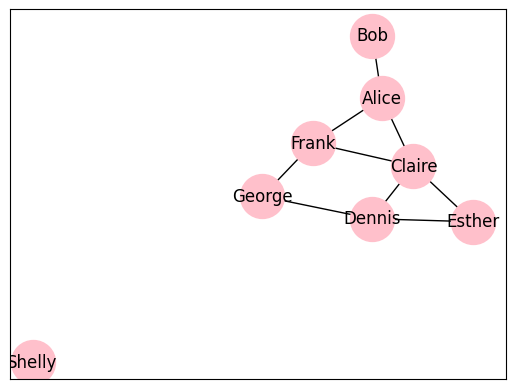

In [69]:
nx.draw_networkx(G=nx.read_adjlist('sample files//amigos.adjlist'), with_labels=True, node_size = 1000, node_color = 'pink')
print(f'Is the Amigos network connected?: {nx.is_connected(G=nx.read_adjlist('sample files//amigos.adjlist'))}')


In directed networks, a strongly connected network has a directed path between every pair of nodes in both directions, while a weakly connected network has connections between all nodes when treated as undirected, but not necessarily in both directions.

Is the Erdos network strongly connected?: False
Is the Erdos network weekly connected?: True


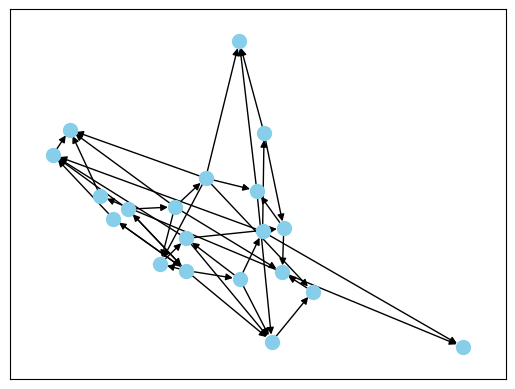

In [70]:
G_erdos = nx.erdos_renyi_graph(20, 0.1, directed=True)
print(f'Is the Erdos network strongly connected?: {nx.is_strongly_connected(G=G_erdos)}')
print(f'Is the Erdos network weekly connected?: {nx.is_weakly_connected(G=G_erdos)}')

nx.draw_networkx(G=G_erdos, with_labels=False, node_size = 100, node_color = 'skyblue')

#### 2.3 Clustering coefficient

The clustering coefficient measures the extent to which nodes in a network tend to form triangles, representing how interconnected a node's neighbors are. It can be calculated for individual nodes or averaged across the network to indicate the overall level of clustering.

In [71]:
cc = nx.clustering(G=G_karate, nodes=[17]) #The function returns a dictionary, you can list more than one node. 
print(f'The clustering coefficiente of node 17 the Karate Club network is: {cc[17]}') 

acc = nx.average_clustering(G=G_karate)
print(f'The average clustering coefficiente of the Karate Club network is: {acc}')

The clustering coefficiente of node 17 the Karate Club network is: 1.0
The average clustering coefficiente of the Karate Club network is: 0.5706384782076823


### 3 - Node characteristics

In this section we will make use of the Game of Thrones network to explore different node characteristics. The edgelist for this network can be accessed from the csv file 'book1.csv'. 

In [72]:
# Reading the csv file
Got_book1 = pd.read_csv('sample files\\book1.csv')

# Creating the network as an undirected graph
GoT_network = nx.Graph()
for _, edge in Got_book1.iterrows(): #Manually adding the edges to the network
    GoT_network.add_edge(edge['Source'], edge['Target'], weight=edge['weight'])

This network includes 187 nodes and 684 weighted edges. To ease the following analyses we will work with a subgraph containing the nodes with more interactions. This subgraph will be named as 'GoT_subnetwork' and will include nodes with weighted degree higher than 100. 

In [73]:
degrees = dict(GoT_network.degree(weight='weight'))
high_degree_nodes = [n for n in GoT_network.nodes() if degrees[n] > 100]

GoT_subnetwork = nx.subgraph(G=GoT_network, nbunch=high_degree_nodes)

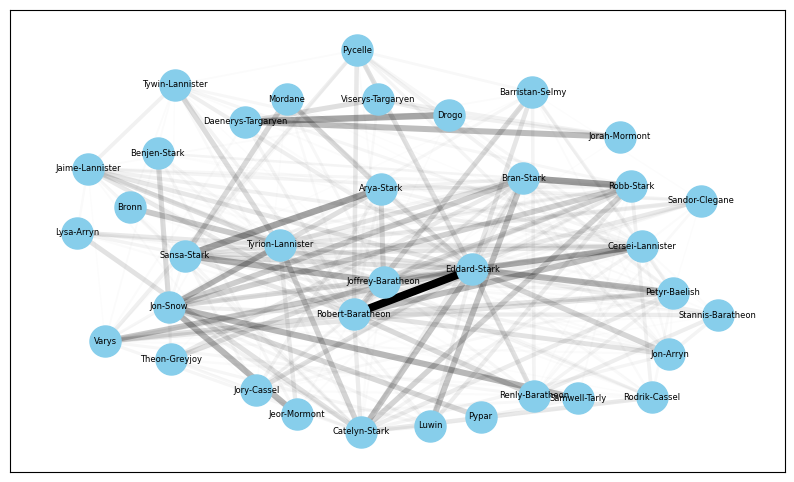

In [74]:
# Visualising the subnetwork 
########################################

pos = nx.spring_layout(G=GoT_subnetwork, weight='weight',iterations=20, k=4) 
fig, ax = plt.subplots(figsize=(10,6))

#Plotting nodes first
nx.draw_networkx_nodes(GoT_subnetwork, pos=pos, node_size=500, node_color='skyblue')

#Adding nodes labels
nx.draw_networkx_labels(GoT_subnetwork, pos=pos, font_size=6) 

#Drawing the weighted edges
weights = [d for (u,v,d) in GoT_subnetwork.edges(data='weight')]  # Will be used to set the edge width
alpha_values = [d/max(weights) for (u,v,d) in GoT_subnetwork.edges(data='weight')]  #Will be used to set the edge transparency (smaller values correspond to weaker edges)
nx.draw_networkx_edges(G=GoT_subnetwork, pos=pos, width=np.log(weights), alpha=alpha_values)

plt.show()

#### 3.1 Centrality measures and distributions

In [75]:
GoT_centralities = pd.DataFrame.from_dict(dict(nx.degree(GoT_subnetwork)), orient='index')
GoT_centralities.columns = ['Degree']
GoT_centralities['Weighted Degree'] = pd.DataFrame.from_dict(dict(nx.degree(GoT_subnetwork, weight='weight')), orient='index')
GoT_centralities['Betweenness'] = pd.DataFrame.from_dict(dict(nx.betweenness_centrality(GoT_subnetwork,normalized=False)), orient='index')  #We should use betweenness with weights when they represent length. 
GoT_centralities['Closeness'] = pd.DataFrame.from_dict(dict(nx.closeness_centrality(GoT_subnetwork, distance='weight')), orient='index')
GoT_centralities['Page Rank'] = pd.DataFrame.from_dict(dict(nx.pagerank(GoT_subnetwork, weight='weight')), orient='index') #Page rank should be used for directed networks. If your network is undirected it will be converted to a directed oned 
GoT_centralities['Eigenvector'] = pd.DataFrame.from_dict(dict(nx.eigenvector_centrality(GoT_subnetwork, weight='weight')), orient='index')

GoT_subnetwork_centralities = GoT_centralities.copy()

This dataframe contains the six centrality measures for each node in the subnetwork:

In [76]:
GoT_subnetwork_centralities.head()

,Degree,Weighted Degree,Betweenness,Closeness,Page Rank,Eigenvector
Catelyn-Stark,20,392,19.382940,0.090674,0.040078,0.183590
Benjen-Stark,10,91,2.753510,0.123239,0.012686,0.028943
Jorah-Mormont,4,109,0.000000,0.083135,0.019596,0.008089
Bran-Stark,19,408,12.244503,0.120690,0.041872,0.134435
Jory-Cassel,14,114,5.262245,0.123239,0.014062,0.069680


These centralities are helpful to analyse the nodes' characteristics regarding their position in the network, importance and influence: 

$\cdot$ **Degree**: It measures the number of different connections a node has, considering all the connections equally important. 

$\cdot$ **Weighted Degree**: It measures the sum of the weightes of all edges connecting to a node, representing the total strenght of such connections. 

$\cdot$ **Betweenness**: It measures how often a node is on the shortest path between two other nodes. 

$\cdot$ **Closeness**: It measures how easily can a node reach every other node in the network. 

$\cdot$ **Page rank**: It measures the importance of a node based on the importance of the incoming links connecting to it. 

$\cdot$ **Eigenvector**: It is based on the idea that a node's influence is amplified by being connected to other influential nodes.

Below is an example of plotting the distribution of these centralities along with the subnetwork visualisation with the nodes sized based on these centralities. In the example, the centrality 'Weighted Degree' is used. You can explore plotting the distributions of other variables. How do the distributions and plots change? 

*Note*: You will notice the node size for some variables would need to be adjusted so the nodes appear in the network plot. You can make this adjustment directly in the node_size parameter. 


Text(0.5, 1.0, 'Node size: Weighted Degree')

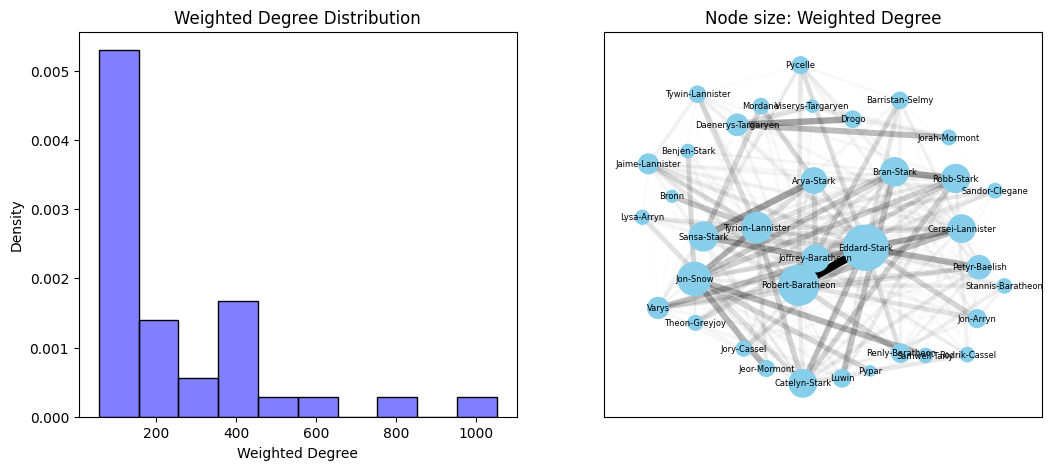

In [77]:
plt.figure(figsize=(26, 5))

variable_name = 'Weighted Degree'

plt.subplot(1,4,1)
sns.histplot(GoT_subnetwork_centralities[variable_name], bins=10, alpha=0.5, color='blue', stat='density')
plt.title(f'{variable_name} Distribution')

plt.subplot(1,4,2)
#Plotting nodes first
nx.draw_networkx_nodes(GoT_subnetwork, pos=pos, node_size=GoT_subnetwork_centralities[variable_name], node_color='skyblue')
#Adding nodes labels
nx.draw_networkx_labels(GoT_subnetwork, pos=pos, font_size=6) 
#Drawing the weighted edges
weights = [d for (u,v,d) in GoT_subnetwork.edges(data='weight')]  # Will be used to set the edge width
alpha_values = [d/max(weights) for (u,v,d) in GoT_subnetwork.edges(data='weight')]  #Will be used to set the edge transparency (smaller values correspond to weaker edges)
nx.draw_networkx_edges(G=GoT_subnetwork, pos=pos, width=np.log(weights), alpha=alpha_values)
plt.title(f'Node size: {variable_name}')

Exploring relatively small networks visually can be an interesting task. However, larger networks become more and more difficult to inspect in a visual way. You can try for example to visualise the full GoT_network, how does it look? How easy or difficult is to draw conclusions about the nodes' connections and their importance or influence?

Centrality measures come handful for exploring and analysing real world networks, that might have thousands (or more!) of nodes and connections, as well as their nodes' characteristics, identifying influencial nodes, etc.  

In the following, we create a similar centralities dataframe for the full GoT_network, and will show an example of how you could use it to get insights into the network structure and its nodes. 

In [78]:
GoT_centralities = pd.DataFrame.from_dict(dict(nx.degree(GoT_network)), orient='index')
GoT_centralities.columns = ['Degree']
GoT_centralities['Weighted Degree'] = pd.DataFrame.from_dict(dict(nx.degree(GoT_network, weight='weight')), orient='index')
GoT_centralities['Betweenness'] = pd.DataFrame.from_dict(dict(nx.betweenness_centrality(GoT_network, normalized=False)), orient='index') #We should use betweenness with weights when they represent length. 
GoT_centralities['Closeness'] = pd.DataFrame.from_dict(dict(nx.closeness_centrality(GoT_network, distance='weight')), orient='index')
GoT_centralities['Page Rank'] = pd.DataFrame.from_dict(dict(nx.pagerank(GoT_network, weight='weight')), orient='index') #Page rank should be used for directed networks. If your network is undirected it will be converted to a directed oned 
GoT_centralities['Eigenvector'] = pd.DataFrame.from_dict(dict(nx.eigenvector_centrality(GoT_network, weight='weight')), orient='index')

GoT_network_centralities = GoT_centralities.copy()

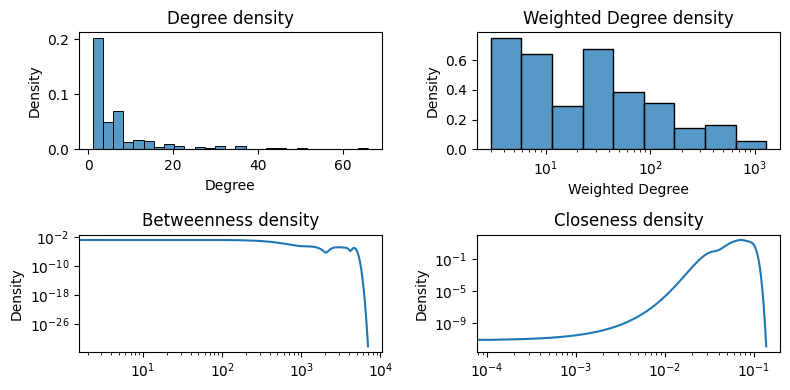

In [79]:
# Insights into network structure
plt.figure(figsize=(8, 4))

plt.subplot(2,2,1)
sns.histplot(data = GoT_network_centralities['Degree'], stat='density')
plt.title('Degree density')

plt.subplot(2,2,2)
sns.histplot(data = GoT_network_centralities['Weighted Degree'], log_scale=True, stat='density')
plt.title('Weighted Degree density')

plt.subplot(2,2,3)
GoT_network_centralities['Betweenness'].plot.density(loglog=True)
plt.title('Betweenness density')

plt.subplot(2,2,4)
GoT_network_centralities['Closeness'].plot.density(loglog=True)
plt.title('Closeness density')

plt.tight_layout()

In [80]:
# Insights into nodes, identifying hubs

#The max function
print(f'The character with highest weighted degree is: {max(GoT_network, key=GoT_network.degree(weight='weight'))}')
print(f'The character with highest closeness is: {max(GoT_network, key=nx.closeness_centrality(GoT_network,distance='weight').get)}')
print(f'The character with highest betweeness is: {max(GoT_network, key=nx.betweenness_centrality(GoT_network).get)}') #We should use betweenness with weights when they represent length. 
print(f'The character with highest page rank is: {max(GoT_network, key=nx.pagerank(GoT_network,weight='weight').get)}') #Page rank should be used for directed networks. If your network is undirected it will be converted to a directed oned 
print(f'The character with highest eigenvector is: {max(GoT_network, key=nx.eigenvector_centrality(GoT_network,weight='weight').get)}')

The character with highest weighted degree is: Eddard-Stark
The character with highest closeness is: Robert-Baratheon
The character with highest betweeness is: Eddard-Stark
The character with highest page rank is: Eddard-Stark
The character with highest eigenvector is: Eddard-Stark


<center> What does this information say about Eddard Stark and Robert-Baratheon in the first book of the series? </center>

In addition to this function, you can use the dataframe that we created before and sort it out based on different centralities, which willl allow you to identify, select, and inspect the $n$ most important nodes. 

#### 3.2 Core decomposition

As we mentioned before, large networks are difficult to visualise. Core decomposition is helpful for this task, by pruning low-degree nodes so we can inspect the denser parts of the whole network. 

In [81]:
#to obtain the core number of all the nodes in the network:
core_numbers = (nx.core_number(G=GoT_network))

A k-core graph is a subgraph where every node has at least k neigboors.

In [82]:
K_core_graph = nx.k_core(G=GoT_network, k=10)
print(f'The k-core subnetwork has {nx.number_of_nodes(G=K_core_graph)} nodes and {nx.number_of_edges(G=K_core_graph)} edges')

The k-core subnetwork has 25 nodes and 192 edges


In contrast, the k-shell is a layer of nodes that are exactly in the k-core but not in the k+1 core. These are the nodes that are removed in the process of obtaining the k-core. 

In [83]:
K_shell_graph = nx.k_shell(G=GoT_network, k=10)
print(f'The shell has {nx.number_of_nodes(G=K_shell_graph)} nodes')

The shell has 2 nodes


How many nodes will be in the next k-core subnetwork (k=11)?  

### 4 - Community detection

#### 4.1 Bridge removal

Girvan-Newman is a bridge removal community detection algorithm that identify such communities by progressively removing edges with the highest betweenness centrality, as these edges often act as bridges between different communitites. As the edges are removed, the network breaks down into smaller subgraphs. Networkx's givan-newman functionwill return a list containing the partitions that form as the edges are removed. 

In [84]:
partitions = list(nx.community.girvan_newman(G_karate))
print(f'The list contains {len(partitions)} partitions')

The list contains 33 partitions


We can also access the list of nodes assigned to each communitiy in each partition. This information is helpful for you to analyse such communities in more detail, or if you want to use this information for visualisations of your comunities. For example, in the first partition generated, the communities are formed as: 

In [85]:
print(partitions[0]) # partitions[0][0] and partitions[0][1] can be used to access/print the set of nodes in each of the communities separately. 

({0, 1, 3, 4, 5, 6, 7, 10, 11, 12, 13, 16, 17, 19, 21}, {2, 8, 9, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33})


How many communities are in the last partition?

#### 4.2 Modularity optimisation

Modularity optimisation referst to finding the partition with the maximum modularity out of a set of n partitions. The modularity of each partition can be computed as follows: 

In [86]:
nx.community.quality.modularity(G_karate, partitions[0]) #Modularity of the first partition generated by the Girvan-newman algorithm, two communities are included. 

0.3476602762317048

The partition with maximum reachable modularity that can be achieved in a given network is given by:

In [87]:
partition_greedy_modularity = nx.community.greedy_modularity_communities(G_karate) #Finds the best partition based on Newman's greedy algorithm
print(partition_greedy_modularity)

[frozenset({8, 14, 15, 18, 20, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33}), frozenset({1, 2, 3, 7, 9, 12, 13, 17, 21}), frozenset({0, 16, 19, 4, 5, 6, 10, 11})]


In [88]:
partition_louvain = nx.community.louvain_communities(G_karate) #Finds the best partition of a graph using the Louvain community detection algorithm. 
print(partition_louvain)

[{0, 1, 2, 3, 7, 11, 12, 13, 17, 19, 21}, {16, 4, 5, 6, 10}, {32, 33, 8, 9, 14, 15, 18, 20, 22, 26, 28, 29, 30}, {23, 24, 25, 27, 31}]


#### 4.3 Label propagation

The communities identified by the label propagation algorithm can be directly obtained in Networkx as follows: 

In [89]:
partition_LP = list(nx.community.asyn_lpa_communities(G_karate))
print(partition_LP)

[{0, 1, 2, 3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 16, 17, 19, 21, 28, 30}, {32, 33, 9, 14, 15, 18, 20, 22, 23, 26, 27, 29}, {24, 25, 31}]


The normalised mutual information score can be used to compare the similarity of the communities identified in each method. To do so, we will assign labels to the communities the nodes belong to under each partition. 

In [90]:
greedy_labels = [None] * len(G_karate.nodes())
louvain_labels = [None] * len(G_karate.nodes())
LP_labels = [None] * len(G_karate.nodes())

for community_index, community in enumerate(partition_greedy_modularity):
    for node in community:
        greedy_labels[node] = community_index

for community_index, community in enumerate(partition_louvain):
    for node in community:
        louvain_labels[node] = community_index

for community_index, community in enumerate(partition_LP):
    for node in community:
        LP_labels[node] = community_index

In [91]:
print(greedy_labels)

[2, 1, 1, 1, 2, 2, 2, 1, 0, 1, 2, 2, 1, 1, 0, 0, 2, 1, 0, 2, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


In [92]:
print(louvain_labels)

[0, 0, 0, 0, 1, 1, 1, 0, 2, 2, 1, 0, 0, 0, 2, 2, 1, 0, 2, 0, 2, 0, 2, 3, 3, 3, 2, 3, 2, 2, 2, 3, 2, 2]


In [93]:
print(LP_labels)

[0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 2, 2, 1, 1, 0, 1, 0, 2, 1, 1]


In [94]:
metrics.normalized_mutual_info_score(greedy_labels, louvain_labels)

np.float64(0.6385282826217605)

In [95]:
metrics.normalized_mutual_info_score(louvain_labels,LP_labels)

np.float64(0.5459173632115474)